## Exercise 1: Understanding Data Visualization

### Why Data Visualization is Important in Data Analysis

Data visualization is a crucial component of data analysis for several key reasons:
* **Identifies Patterns and Trends:** It helps human analysts quickly spot trends, correlations, and patterns within complex datasets that might be difficult to detect in raw tables of numbers.
* **Simplifies Complex Data:** Large volumes of multi-dimensional data can be simplified and digested quickly when represented visually.
* **Aids Decision Making:** Clearly presented visuals facilitate faster and more informed decision-making for both technical and non-technical stakeholders.
* **Detects Anomalies and Outliers:** Visual outliers immediately stand out in graphs (like scatter plots or box plots), flagging data quality issues or unique analytical insights.

---

### Purpose of a Line Graph in Data Visualization

A **line graph** (or line chart) is primarily used to **display information as a series of data points connected by straight line segments**.
* **Tracks Changes Over Time:** Its most common purpose is to visualize continuous trends, fluctuations, and developments over sequential intervals (e.g., daily sales, monthly temperature changes, or annual stock prices).
* **Shows Relationships:** It demonstrates the relationship between two continuous variables, typically with time or another independent variable on the horizontal axis (X-axis) and the dependent variable on the vertical axis (Y-axis).

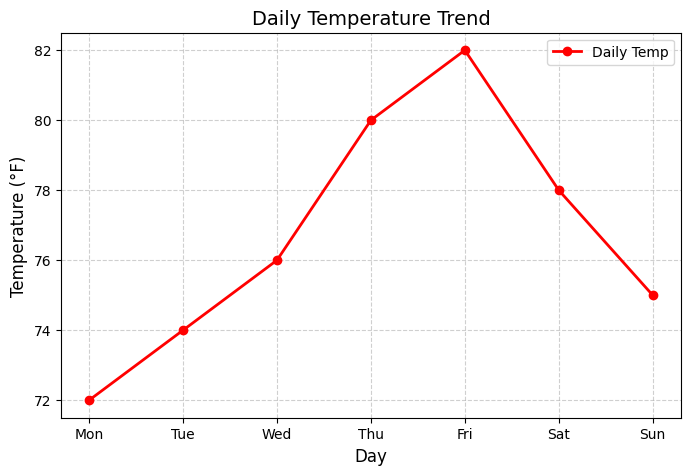

In [3]:
import matplotlib.pyplot as plt

# Data: Days of the week and corresponding temperature values
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
temperatures = [72, 74, 76, 80, 82, 78, 75]

# Create the plot
plt.figure(figsize=(8, 5))
plt.plot(days, temperatures, marker='o', color='r', linestyle='-', linewidth=2, label='Daily Temp')

# Add labels and a title
plt.title('Daily Temperature Trend', fontsize=14)
plt.xlabel('Day', fontsize=12)
plt.ylabel('Temperature (°F)', fontsize=12)

# Customize chart details
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Display the plot
plt.show()

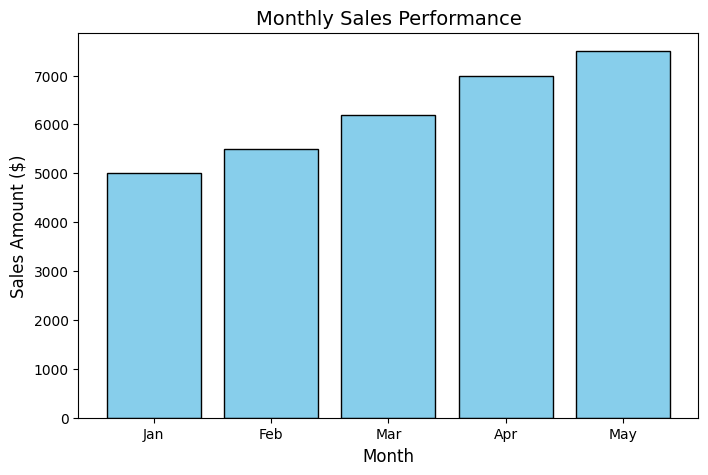

In [4]:
import matplotlib.pyplot as plt

# Data: Months and corresponding sales values
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May']
sales_amounts = [5000, 5500, 6200, 7000, 7500]

# Create the bar chart
plt.figure(figsize=(8, 5))
plt.bar(months, sales_amounts, color='skyblue', edgecolor='black')

# Add labels and a title
plt.xlabel('Month', fontsize=12)
plt.ylabel('Sales Amount ($)', fontsize=12)
plt.title('Monthly Sales Performance', fontsize=14)

# Display the plot
plt.show()

Columns in dataset: ['Timestamp', 'Choose your gender', 'Age', 'What is your course?', 'Your current year of Study', 'What is your CGPA?', 'Marital status', 'Do you have Depression?', 'Do you have Anxiety?', 'Do you have Panic attack?', 'Did you seek any specialist for a treatment?']


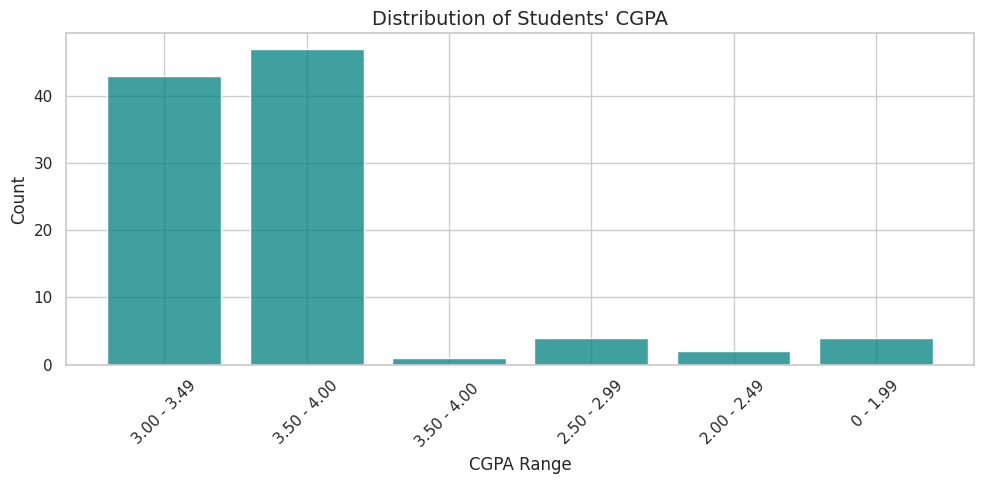

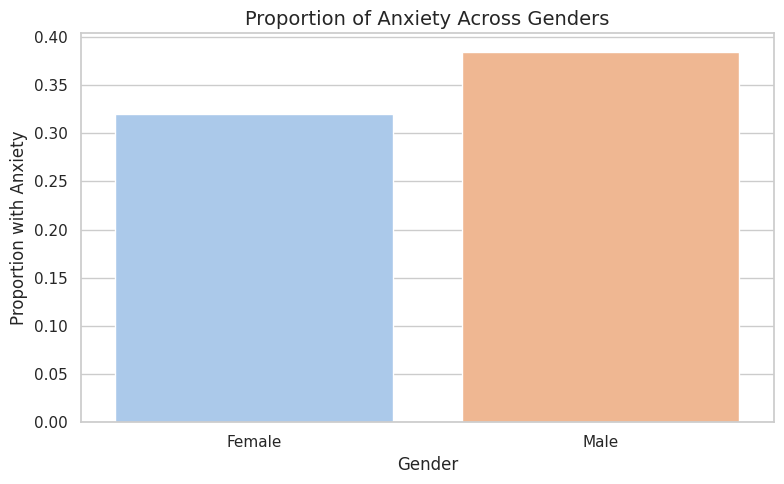

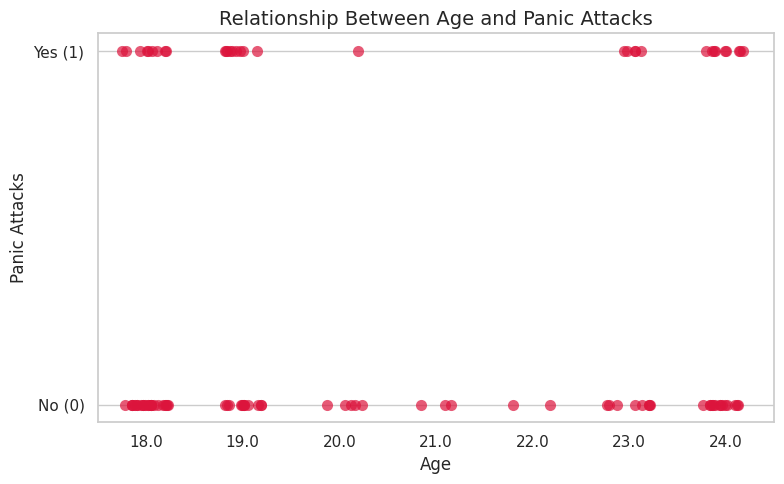

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/Student Mental health.csv')

# Clean column names by stripping whitespace
df.columns = df.columns.str.strip()

# Print columns to help identify correct names
print("Columns in dataset:", list(df.columns))

# Dynamically locate columns to prevent KeyErrors
cgpa_col = [col for col in df.columns if 'CGPA' in col][0]
anxiety_col = [col for col in df.columns if 'Anxiety' in col][0]
panic_col = [col for col in df.columns if 'Panic' in col][0]
gender_col = [col for col in df.columns if 'gender' in col or 'Gender' in col][0]
age_col = [col for col in df.columns if 'Age' in col or 'age' in col][0]

# Set the aesthetic style for the plots
sns.set_theme(style="whitegrid")

# =========================================================================
# Exercise 4: Visualizing the Distribution of CGPA
# =========================================================================
plt.figure(figsize=(10, 5))
# Sort the unique CGPA values cleanly
sorted_cgpa = sorted(df[cgpa_col].dropna().unique())

sns.histplot(data=df, x=cgpa_col, color='teal', shrink=0.8)
plt.title('Distribution of Students\' CGPA', fontsize=14)
plt.xlabel('CGPA Range', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# =========================================================================
# Exercise 5: Comparing Anxiety Levels Across Different Genders
# =========================================================================
plt.figure(figsize=(8, 5))
# To plot proportion, map anxiety 'Yes'/'No' to numeric 1/0
df['Anxiety_Numeric'] = df[anxiety_col].map({'Yes': 1, 'No': 0})

sns.barplot(data=df, x=gender_col, y='Anxiety_Numeric', hue=gender_col, palette='pastel', legend=False, errorbar=None)
plt.title('Proportion of Anxiety Across Genders', fontsize=14)
plt.xlabel('Gender', fontsize=12)
plt.ylabel('Proportion with Anxiety', fontsize=12)
plt.tight_layout()
plt.show()

# =========================================================================
# Exercise 6: Exploring the Relationship Between Age and Panic Attacks
# =========================================================================
plt.figure(figsize=(8, 5))
# Convert panic attack responses to numeric values (Yes=1, No=0)
df['Panic_Attacks_Numeric'] = df[panic_col].map({'Yes': 1, 'No': 0})

# Using a stripplot to introduce jitter so overlapping categorical data points are visible
sns.stripplot(data=df, x=age_col, y='Panic_Attacks_Numeric', size=8, color='crimson', alpha=0.7, jitter=0.25)
plt.title('Relationship Between Age and Panic Attacks', fontsize=14)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Panic Attacks', fontsize=12)
plt.yticks([0, 1], ['No (0)', 'Yes (1)'])
plt.tight_layout()
plt.show()